In [3]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

EDA

In [4]:
df = pd.read_csv('gender_classification_v7.csv')

In [5]:
df.head(5)

,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
0,1,11.8,6.1,1,0,1,1,Male
1,0,14.0,5.4,0,0,1,0,Female
2,0,11.8,6.3,1,1,1,1,Male
3,0,14.4,6.1,0,1,1,1,Male
4,1,13.5,5.9,0,0,0,0,Female


In [6]:
df.shape

(5001, 8)

In [7]:
df.describe

<bound method NDFrame.describe of       long_hair  forehead_width_cm  forehead_height_cm  nose_wide  nose_long  \
0             1               11.8                 6.1          1          0   
1             0               14.0                 5.4          0          0   
2             0               11.8                 6.3          1          1   
3             0               14.4                 6.1          0          1   
4             1               13.5                 5.9          0          0   
...         ...                ...                 ...        ...        ...   
4996          1               13.6                 5.1          0          0   
4997          1               11.9                 5.4          0          0   
4998          1               12.9                 5.7          0          0   
4999          1               13.2                 6.2          0          0   
5000          1               15.4                 5.4          1          1   

     

In [8]:
df.info

<bound method DataFrame.info of       long_hair  forehead_width_cm  forehead_height_cm  nose_wide  nose_long  \
0             1               11.8                 6.1          1          0   
1             0               14.0                 5.4          0          0   
2             0               11.8                 6.3          1          1   
3             0               14.4                 6.1          0          1   
4             1               13.5                 5.9          0          0   
...         ...                ...                 ...        ...        ...   
4996          1               13.6                 5.1          0          0   
4997          1               11.9                 5.4          0          0   
4998          1               12.9                 5.7          0          0   
4999          1               13.2                 6.2          0          0   
5000          1               15.4                 5.4          1          1   

      l

In [9]:
df.isnull().sum()

long_hair                    0
forehead_width_cm            0
forehead_height_cm           0
nose_wide                    0
nose_long                    0
lips_thin                    0
distance_nose_to_lip_long    0
gender                       0
dtype: int64

Data Visualization

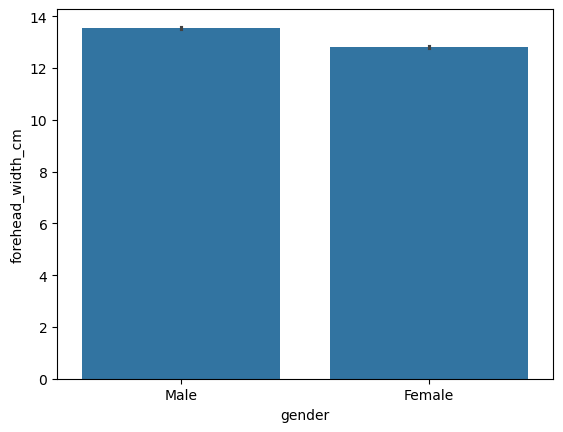

In [10]:
sns.barplot(x='gender', y='forehead_width_cm', data= df)
plt.show()

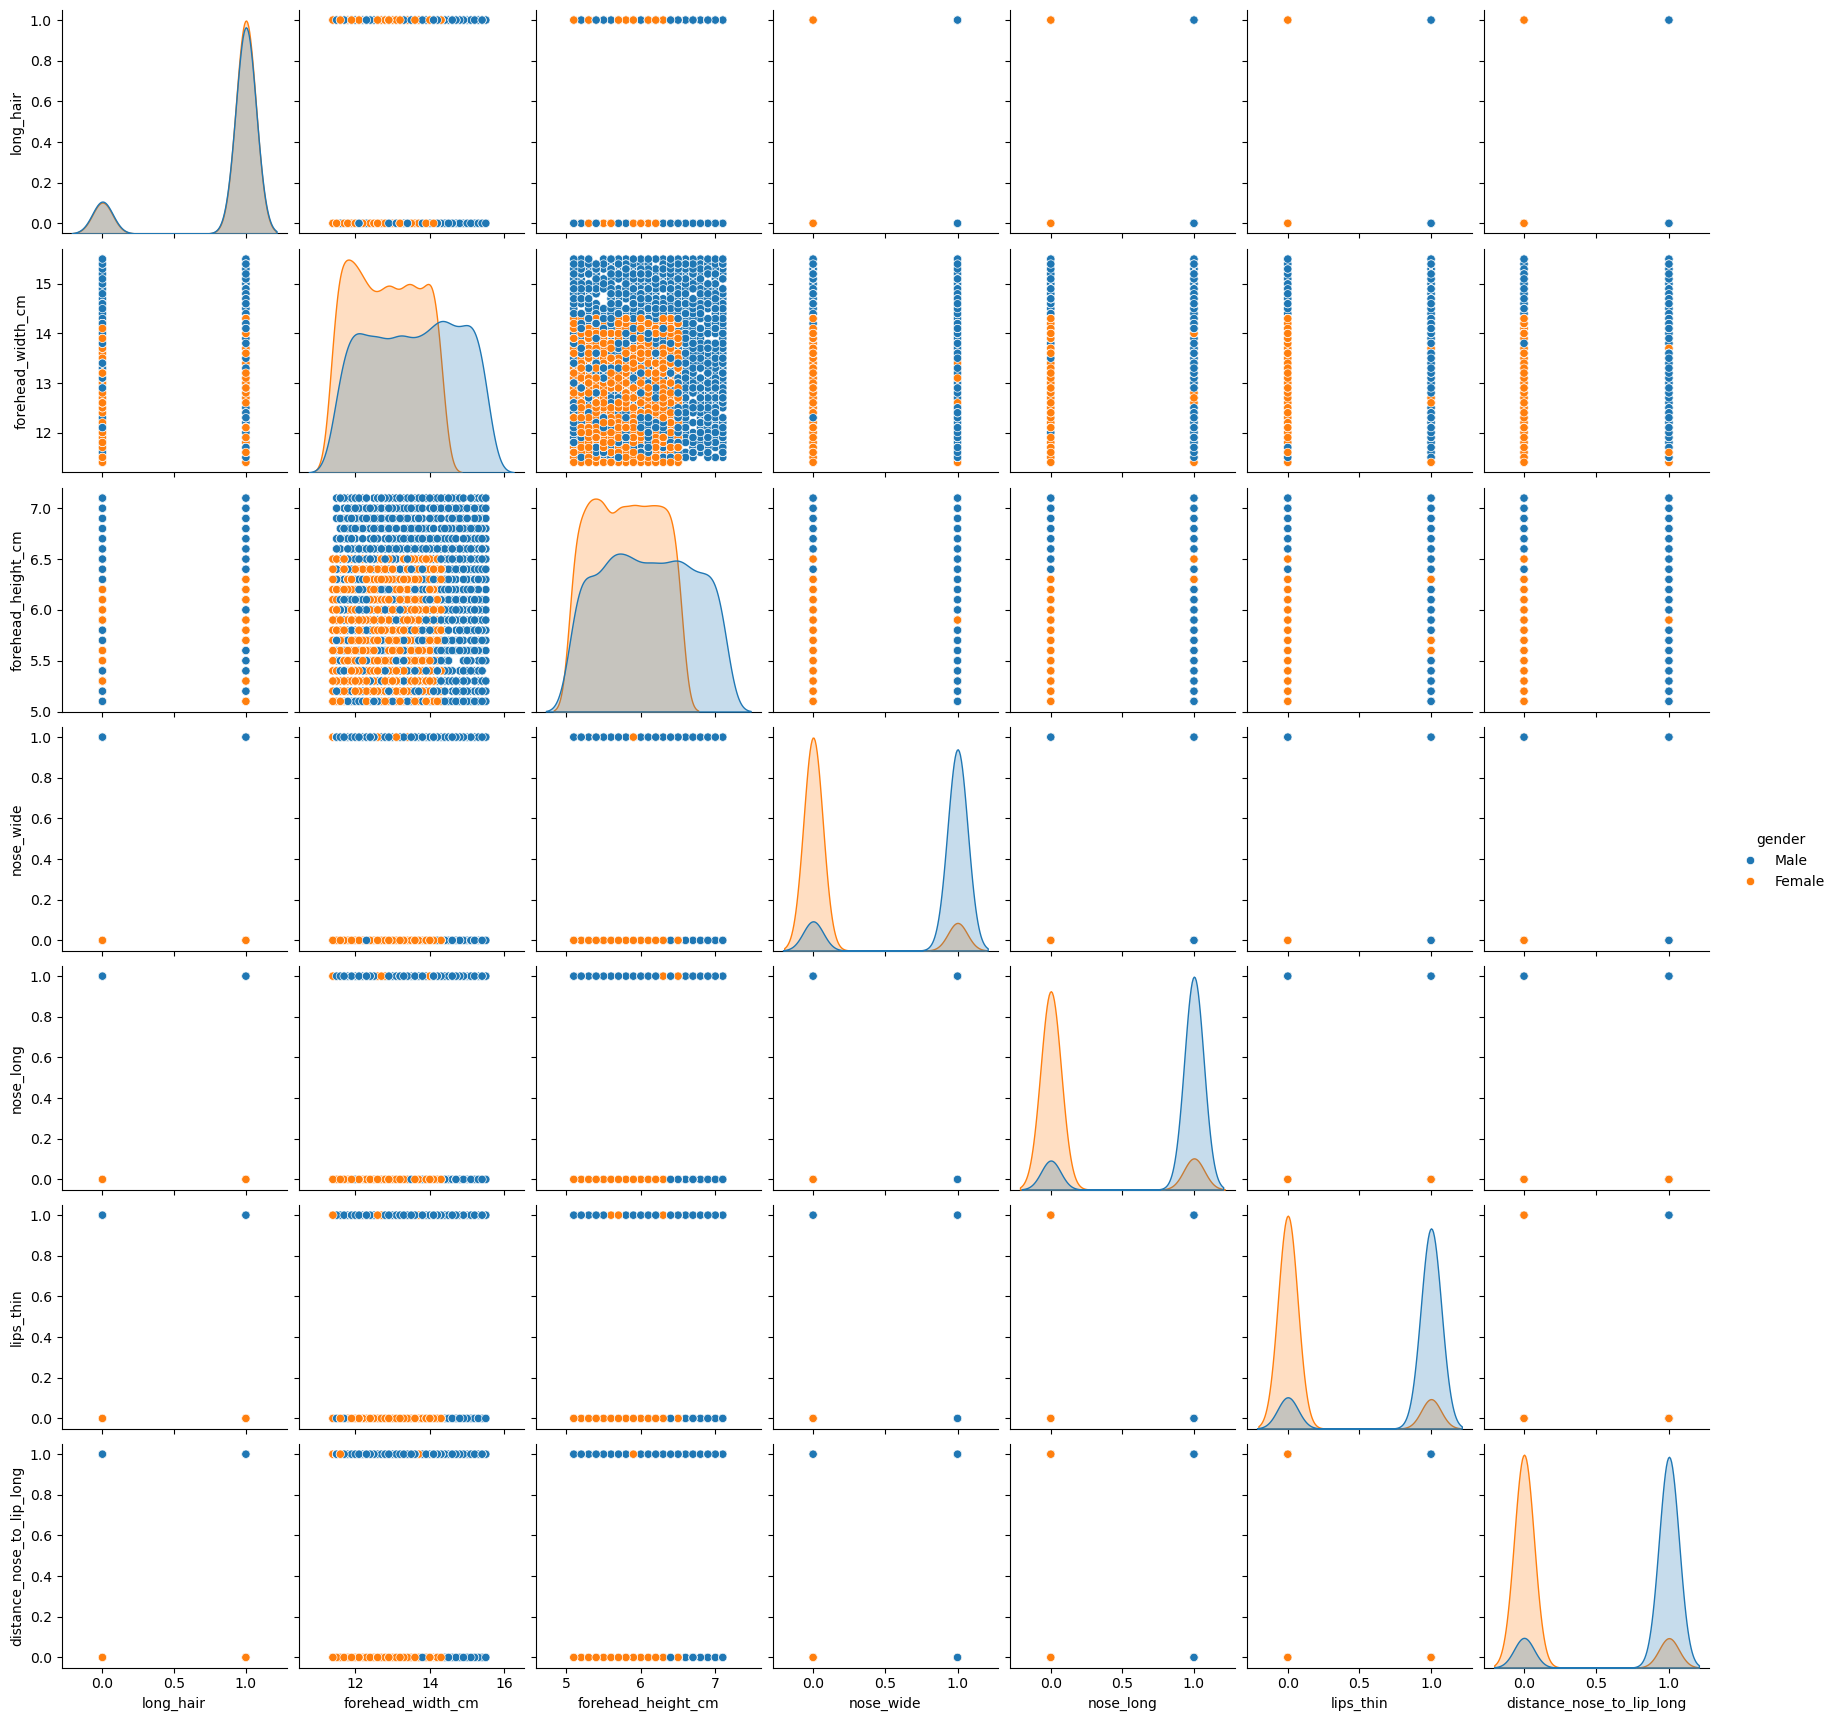

In [11]:
sns.pairplot(data=df,hue='gender')
plt.show()

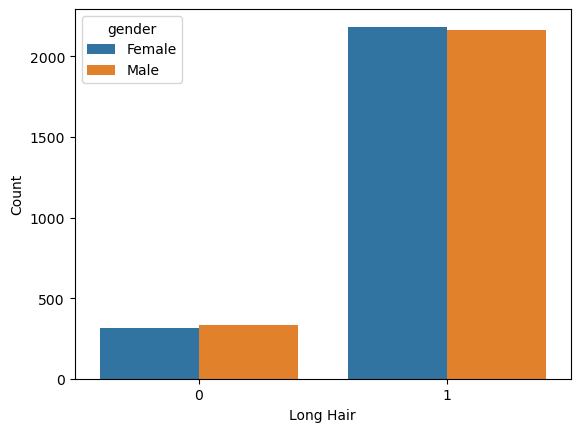

In [12]:
sns.countplot(x='long_hair',hue='gender', data=df)
plt.xlabel('Long Hair')
plt.ylabel('Count')
plt.show()

In [13]:
from sklearn.preprocessing import LabelEncoder
le =LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])

In [14]:
df.head(5)

,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
0,1,11.8,6.1,1,0,1,1,1
1,0,14.0,5.4,0,0,1,0,0
2,0,11.8,6.3,1,1,1,1,1
3,0,14.4,6.1,0,1,1,1,1
4,1,13.5,5.9,0,0,0,0,0


In [15]:
corr = df.corr()['gender'].sort_values(ascending=False)
print('Correlation: ')
print(corr)

Correlation: 
gender                       1.000000
nose_wide                    0.758502
distance_nose_to_lip_long    0.754850
nose_long                    0.744147
lips_thin                    0.743319
forehead_width_cm            0.334125
forehead_height_cm           0.277190
long_hair                   -0.010767
Name: gender, dtype: float64


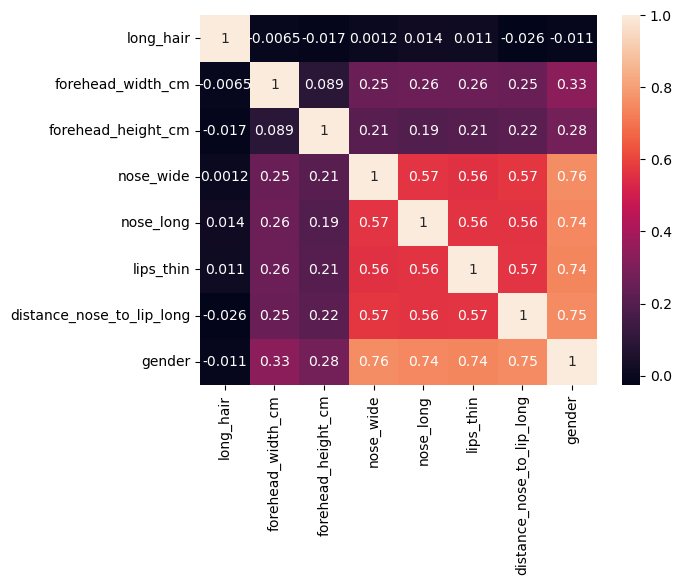

In [16]:

sns.heatmap(df.corr(), annot=True)
plt.show()


In [17]:
X = df.drop('gender', axis=1)
y = df['gender']

Data Splitting

In [18]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=10)

In [19]:
print(f'X_train.shape = {X_train.shape}')
print(f'y_train.shape = {y_train.shape}')
print(f'X_test.shape = {X_test.shape}')
print(f'y_test.shape = {y_test.shape}')

X_train.shape = (3750, 7)
y_train.shape = (3750,)
X_test.shape = (1251, 7)
y_test.shape = (1251,)


In [20]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


DATA CLEANING

In [21]:
df.fillna(0, inplace=True)
print(df.shape)

(5001, 8)


In [22]:
df.fillna("Missing", inplace=True)
print(df.shape)


(5001, 8)


In [23]:
df.fillna(df.mean(), inplace=True)
print(df.shape)

(5001, 8)


In [24]:
value=0
df.fillna(value, inplace=True)
print(df.shape)

(5001, 8)


In [25]:
df.drop_duplicates(inplace=True)
print(df.shape)

(3233, 8)


In [26]:
df.dropna(inplace=True)
print(df.shape)

(3233, 8)


ML Models

Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [28]:
y_pred_lr = lr.predict(X_test)

In [29]:
from sklearn.metrics import accuracy_score
acc_lr = round(accuracy_score(y_test, y_pred_lr) * 100, 2)
print(f'Accuracy score for Logistic Regression = {acc_lr}')

Accuracy score for Logistic Regression = 97.28


In [30]:
from sklearn.metrics import confusion_matrix, classification_report
print(f'Confusion Matrix: \n{confusion_matrix(y_test, y_pred_lr)}')
print(f'Classification Report: \n{classification_report(y_test, y_pred_lr)}')

Confusion Matrix: 
[[598  18]
 [ 16 619]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       616
           1       0.97      0.97      0.97       635

    accuracy                           0.97      1251
   macro avg       0.97      0.97      0.97      1251
weighted avg       0.97      0.97      0.97      1251



<Axes: >

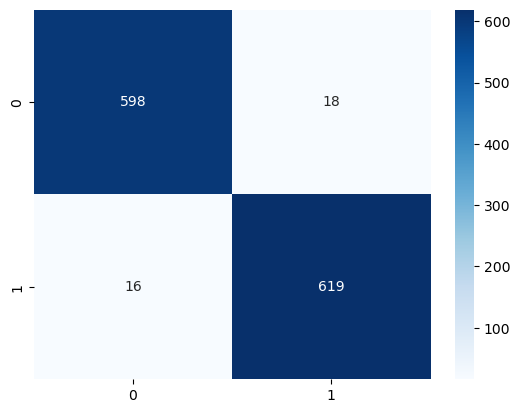

In [31]:
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues')

SVC

In [32]:
from sklearn.svm import SVC
svc = SVC()
svc.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [33]:
y_pred_svc = svc.predict(X_test)

In [34]:
acc_svc = round(accuracy_score(y_test, y_pred_svc) * 100, 2)
print(f'Accuracy score for SVC = {acc_svc}')

Accuracy score for SVC = 97.52


<Axes: >

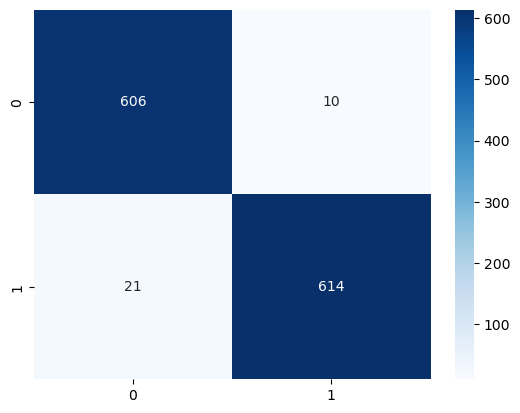

In [35]:
sns.heatmap(confusion_matrix(y_test, y_pred_svc), annot=True, fmt='d', cmap='Blues')

DECISION TREE

In [36]:
from sklearn.tree import DecisionTreeClassifier

# Initialize and fit the model
dt = DecisionTreeClassifier(max_depth=7, min_samples_split=10, random_state=44)
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,7
,min_samples_split,10
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,44
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [37]:
y_pred_dt = dt.predict(X_test)

In [38]:
acc_dt = round(accuracy_score(y_test, y_pred_dt) * 100, 2)
print(f'Accuracy score for Decision Tree = {acc_dt}')

Accuracy score for Decision Tree = 97.52


In [39]:
print(f'Confusion Matrix: \n{confusion_matrix(y_test, y_pred_dt)}')
print(f'Classification Report: \n{classification_report(y_test, y_pred_dt)}')

Confusion Matrix: 
[[601  15]
 [ 16 619]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       616
           1       0.98      0.97      0.98       635

    accuracy                           0.98      1251
   macro avg       0.98      0.98      0.98      1251
weighted avg       0.98      0.98      0.98      1251



<Axes: >

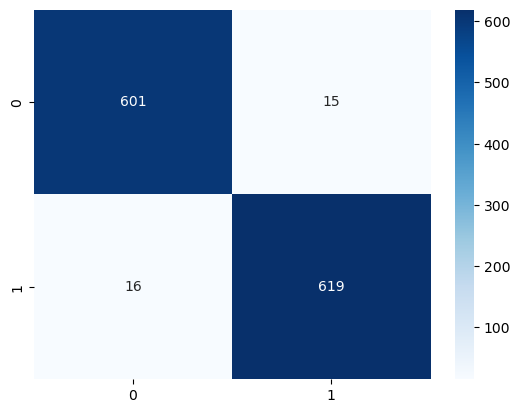

In [40]:
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues')

RANDOM FOREST

In [41]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and fit the model
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=44)
rf.fit(X_train, y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [42]:
y_pred_rf = rf.predict(X_test)

In [43]:
acc_rf = round(accuracy_score(y_test, y_pred_rf) * 100, 2)
print(f'Accuracy score for Random Forest = {acc_rf}')

Accuracy score for Random Forest = 98.08


In [44]:
print(f'Confusion Matrix: \n{confusion_matrix(y_test, y_pred_rf)}')
print(f'Classification Report: \n{classification_report(y_test, y_pred_rf)}')

Confusion Matrix: 
[[607   9]
 [ 15 620]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       616
           1       0.99      0.98      0.98       635

    accuracy                           0.98      1251
   macro avg       0.98      0.98      0.98      1251
weighted avg       0.98      0.98      0.98      1251



<Axes: >

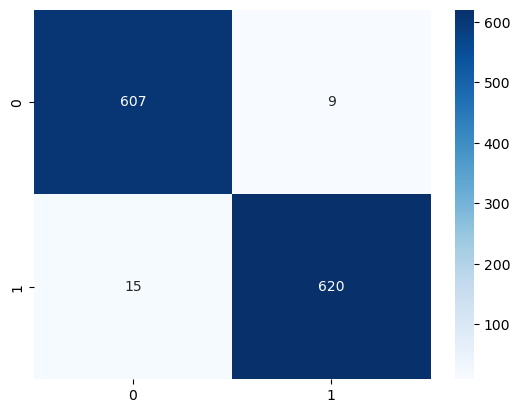

In [45]:
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues')

KNN

In [46]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize and fit the model
knn = KNeighborsClassifier(n_neighbors=100)
knn.fit(X_train, y_train)


,n_neighbors,100
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [47]:
y_pred_knn = knn.predict(X_test)

In [48]:
acc_knn = round(accuracy_score(y_test, y_pred_knn) * 100, 2)
print(f'Accuracy score for KNN = {acc_knn}')

Accuracy score for KNN = 98.0


In [49]:
print(f'Confusion Matrix: \n{confusion_matrix(y_test, y_pred_knn)}')
print(f'Classification Report: \n{classification_report(y_test, y_pred_knn)}')

Confusion Matrix: 
[[611   5]
 [ 20 615]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       616
           1       0.99      0.97      0.98       635

    accuracy                           0.98      1251
   macro avg       0.98      0.98      0.98      1251
weighted avg       0.98      0.98      0.98      1251



<Axes: >

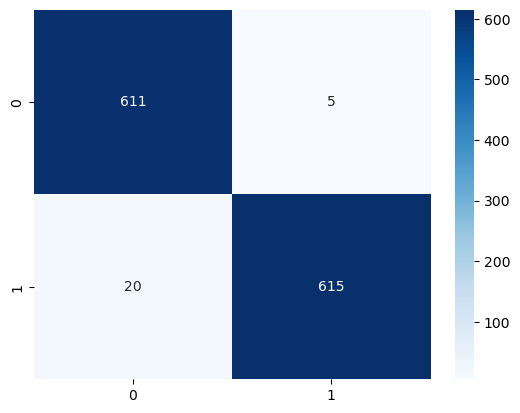

In [50]:
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Blues')

COMPARE BETWEEN MODELS

In [51]:
data_df = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVC',
        'Decision Tree',
        'Random Forest',
        'KNN',
    ],
    'Accuracy': [
        acc_lr,
        acc_svc,
        acc_dt,
        acc_rf,
        acc_knn,
    ]
}).sort_values(by='Accuracy', ascending=False)

In [52]:
data_df

,Model,Accuracy
3,Random Forest,98.08
4,KNN,98.00
1,SVC,97.52
2,Decision Tree,97.52
0,Logistic Regression,97.28


In [53]:
print(df.columns.tolist())

['long_hair', 'forehead_width_cm', 'forehead_height_cm', 'nose_wide', 'nose_long', 'lips_thin', 'distance_nose_to_lip_long', 'gender']


In [54]:
import pickle

with open("model.pkl", "wb") as f:
    pickle.dump(rf, f)   # replace `rf` with whatever variable name your Random Forest model is stored in

In [55]:
import pickle

best_model = rf   # change 'rf' to your actual Random Forest variable name

with open("model.pkl", "wb") as f:
    pickle.dump(best_model, f)

feature_columns = list(X.columns)   # change 'X' to your actual features variable
with open("columns.pkl", "wb") as f:
    pickle.dump(feature_columns, f)

print("Saved successfully")
print(feature_columns)

Saved successfully
['long_hair', 'forehead_width_cm', 'forehead_height_cm', 'nose_wide', 'nose_long', 'lips_thin', 'distance_nose_to_lip_long']


In [56]:
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Scaler saved")

Scaler saved


In [57]:
df['gender'].unique()


array([1, 0])

In [ ]:
-